# Comprensión de los datos, EDA y preparación

## 1. Carga de los datos

Se carga el archivo original proporcionado por la institución.
En esta etapa se revisará su estructura y calidad, sin modificar
los registros ni aplicar transformaciones.


In [4]:
from pathlib import Path
import sys

import pandas as pd


directorio_actual = Path.cwd()

if (directorio_actual / "src").is_dir():
    ROOT = directorio_actual
elif (directorio_actual.parent / "src").is_dir():
    ROOT = directorio_actual.parent
else:
    raise FileNotFoundError(
        "Abre el notebook desde la raíz del proyecto "
        "o desde su carpeta notebooks."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.utils import load_raw


df = load_raw()

df.head()


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


## 2. Diagnóstico inicial de calidad

### 2.1. Dimensiones y tipos de datos

Se revisa la cantidad de registros y columnas, los tipos detectados
por pandas y el número de valores no ausentes por variable.

In [5]:
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")

df.info(verbose=True, show_counts=True)

Filas: 2,930
Columnas: 82
<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17 

In [6]:
resumen_nulos = pd.DataFrame({
    "cantidad_nulos": df.isna().sum(),
    "porcentaje_nulos": df.isna().mean().mul(100).round(2)
})

resumen_nulos = resumen_nulos.sort_values(
    "cantidad_nulos",
    ascending=False
)

resumen_nulos.loc[resumen_nulos["cantidad_nulos"] > 0]

,cantidad_nulos,porcentaje_nulos
Pool QC,2917,99.56
Misc Feature,2824,96.38
Alley,2732,93.24
Fence,2358,80.48
Mas Vnr Type,1775,60.58
Fireplace Qu,1422,48.53
Lot Frontage,490,16.72
Garage Qual,159,5.43
Garage Yr Blt,159,5.43
Garage Cond,159,5.43


### 2.2. Revisión de valores ausentes

Las columnas con mayor proporción de valores interpretados como ausentes
son Pool QC (99,56%), Misc Feature (96,38%), Alley (93,24%) y Fence (80,48%).

También destacan Mas Vnr Type (60,58%), Fireplace Qu (48,53%) y
Lot Frontage (16,72%).

Estos porcentajes no justifican por sí solos eliminar las variables.
Antes de definir su tratamiento, se revisará si las ausencias representan
información desconocida, inexistencia de una característica o una
categoría convertida automáticamente en nulo durante la lectura del CSV.

En esta etapa solo se documenta el diagnóstico; no se modifica el dataset.

In [7]:
# Lectura auxiliar para inspeccionar los textos originales del CSV.
df_texto = load_raw(
    dtype=str,
    keep_default_na=False
)

columnas_revisar = [
    "Pool QC",
    "Misc Feature",
    "Alley",
    "Fence",
    "Mas Vnr Type",
    "Fireplace Qu"
]

for columna in columnas_revisar:
    print(f"\n--- {columna} ---")
    print(df_texto[columna].value_counts(dropna=False))


--- Pool QC ---
Pool QC
NA    2917
Ex       4
Gd       4
TA       3
Fa       2
Name: count, dtype: int64

--- Misc Feature ---
Misc Feature
NA      2824
Shed      95
Gar2       5
Othr       4
Elev       1
TenC       1
Name: count, dtype: int64

--- Alley ---
Alley
NA      2732
Grvl     120
Pave      78
Name: count, dtype: int64

--- Fence ---
Fence
NA       2358
MnPrv     330
GdPrv     118
GdWo      112
MnWw       12
Name: count, dtype: int64

--- Mas Vnr Type ---
Mas Vnr Type
None       1752
BrkFace     880
Stone       249
BrkCmn       25
             23
CBlock        1
Name: count, dtype: int64

--- Fireplace Qu ---
Fireplace Qu
NA    1422
Gd     744
TA     600
Fa      75
Po      46
Ex      43
Name: count, dtype: int64


### 2.3. Comprobación de los valores originales

La lectura auxiliar permitió identificar que parte de los valores
detectados inicialmente como nulos corresponden a códigos escritos
en el archivo original.

En Mas Vnr Type se encontraron 1.752 registros con el texto "None"
y 23 campos vacíos. La lectura inicial agrupaba ambas situaciones
como 1.775 valores ausentes, por lo que es necesario diferenciarlas.

En Pool QC, Misc Feature, Alley, Fence y Fireplace Qu se encontró
el código "NA". Su interpretación deberá considerar el significado
de cada variable y su coherencia con otras características de la vivienda.

No se eliminarán estas columnas únicamente por su porcentaje inicial
de valores ausentes. El tratamiento definitivo se establecerá durante
la preparación de datos y quedará documentado.

La lectura auxiliar se utiliza solo para inspeccionar los códigos
originales. El DataFrame principal todavía no se modifica.

In [8]:
resumen_integridad = pd.Series({
    "filas": len(df),
    "columnas": df.shape[1],
    "filas_completamente_duplicadas": df.duplicated().sum(),
    "Order_duplicados": df["Order"].duplicated().sum(),
    "PID_duplicados": df["PID"].duplicated().sum(),
    "SalePrice_nulos": df["SalePrice"].isna().sum(),
    "SalePrice_cero_o_negativo": df["SalePrice"].le(0).sum()
})

resumen_integridad

filas                             2930
columnas                            82
filas_completamente_duplicadas       0
Order_duplicados                     0
PID_duplicados                       0
SalePrice_nulos                      0
SalePrice_cero_o_negativo            0
dtype: int64

### 2.4. Duplicados e integridad de la variable objetivo

El dataset contiene 2.930 registros y 82 columnas.

No se encontraron filas completamente duplicadas ni valores repetidos
en los identificadores Order y PID.

La variable objetivo SalePrice no presenta valores ausentes, iguales
a cero ni negativos.

Por estos criterios no se requiere eliminar registros. Sin embargo,
todavía deben revisarse los rangos de las variables, las posibles
inconsistencias y los valores extremos.

### 2.5. Revisión de rangos numéricos

Se inspeccionan mínimos, máximos, mediana y cuartiles para identificar
valores que requieran revisión.

Un valor extremo no se considerará automáticamente un error ni será
eliminado sin analizar su contexto.

In [9]:
resumen_numerico = (
    df.drop(columns=["Order", "PID"])
      .describe()
      .T
)

resumen_numerico[
    ["count", "min", "25%", "50%", "75%", "max"]
].round(2)

,count,min,25%,50%,75%,max
MS SubClass,2930.0,20.0,20.00,50.0,70.00,190.0
Lot Frontage,2440.0,21.0,58.00,68.0,80.00,313.0
Lot Area,2930.0,1300.0,7440.25,9436.5,11555.25,215245.0
Overall Qual,2930.0,1.0,5.00,6.0,7.00,10.0
Overall Cond,2930.0,1.0,5.00,5.0,6.00,9.0
Year Built,2930.0,1872.0,1954.00,1973.0,2001.00,2010.0
Year Remod/Add,2930.0,1950.0,1965.00,1993.0,2004.00,2010.0
Mas Vnr Area,2907.0,0.0,0.00,0.0,164.00,1600.0
BsmtFin SF 1,2929.0,0.0,0.00,370.0,734.00,5644.0
BsmtFin SF 2,2929.0,0.0,0.00,0.0,0.00,1526.0


### 2.6. Comprobación de coherencia temporal

El resumen numérico muestra un valor de 2207 en Garage Yr Blt,
superior al año máximo de venta registrado (2010).

Se revisarán los registros cuyo año de construcción, remodelación
o construcción del garaje sea posterior al año de venta.

Estas comprobaciones generan alertas para inspección. No modifican
los datos ni implican eliminar automáticamente los registros.

In [10]:
alertas_temporales = pd.DataFrame({
    "construccion_posterior_venta":
        df["Year Built"] > df["Yr Sold"],

    "remodelacion_posterior_venta":
        df["Year Remod/Add"] > df["Yr Sold"],

    "garaje_posterior_venta":
        df["Garage Yr Blt"] > df["Yr Sold"]
})

display(alertas_temporales.sum().rename("cantidad_alertas"))

columnas_revision = [
    "Order",
    "PID",
    "Year Built",
    "Year Remod/Add",
    "Garage Yr Blt",
    "Yr Sold",
    "Garage Type",
    "SalePrice"
]

display(
    df.loc[
        alertas_temporales.any(axis=1),
        columnas_revision
    ]
)

construccion_posterior_venta    1
remodelacion_posterior_venta    3
garaje_posterior_venta          2
Name: cantidad_alertas, dtype: int64

,Order,PID,Year Built,Year Remod/Add,Garage Yr Blt,Yr Sold,Garage Type,SalePrice
1702,1703,528120010,2007,2008,2007.0,2007,Detchd,260116
2180,2181,908154195,2008,2009,2008.0,2007,Attchd,183850
2181,2182,908154205,2007,2008,2007.0,2007,BuiltIn,184750
2260,2261,916384070,2006,2007,2207.0,2007,Attchd,267300


#### Resultado de la revisión temporal

Se identificaron cuatro registros con al menos una alerta temporal:

- Un registro presenta un año de construcción posterior al año de venta.
- Tres registros presentan un año de remodelación posterior al de venta.
- Dos registros presentan un año de construcción del garaje posterior
  al de venta.

Las categorías se superponen: las seis alertas corresponden a cuatro
registros distintos.

Destaca el registro Order = 2261, cuyo año de construcción del garaje
es 2207. Se considera una inconsistencia que requiere tratamiento,
pero no se dispone de evidencia para asignarle un año correcto.

Los demás registros también requieren revisión. Las diferencias
temporales no permiten determinar por sí solas qué campo es incorrecto.

Por ahora se conservan todos los registros sin modificar. Su tratamiento
se definirá y justificará en la etapa de preparación de datos.

### 2.7. Detección exploratoria de valores extremos

Se revisarán Lot Area, Gr Liv Area, Total Bsmt SF y SalePrice
mediante la regla del rango intercuartílico (IQR).

El IQR es la diferencia entre el tercer y el primer cuartil:
IQR = Q3 - Q1.

Se marcarán para revisión los valores inferiores a Q1 - 1,5 × IQR
o superiores a Q3 + 1,5 × IQR.

Esta regla identifica observaciones potencialmente atípicas,
pero no demuestra que sean errores. No se eliminarán ni modificarán
registros únicamente por superar estos límites.

Los límites calculados en esta sección se utilizarán solo para
el diagnóstico exploratorio, no como reglas de limpieza del modelo.

In [11]:
variables_revisar = [
    "Lot Area",
    "Gr Liv Area",
    "Total Bsmt SF",
    "SalePrice"
]

resultados_iqr = []

for columna in variables_revisar:
    serie = df[columna].dropna()

    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    fuera_de_rango = (
        (serie < limite_inferior)
        | (serie > limite_superior)
    )

    resultados_iqr.append({
        "variable": columna,
        "limite_inferior": limite_inferior,
        "limite_superior": limite_superior,
        "cantidad_marcada": fuera_de_rango.sum(),
        "porcentaje_sobre_validos": fuera_de_rango.mean() * 100
    })

resumen_iqr = pd.DataFrame(resultados_iqr).set_index("variable")

resumen_iqr.round(2)

,limite_inferior,limite_superior,cantidad_marcada,porcentaje_sobre_validos
variable,,,,
Lot Area,1267.75,17727.75,127,4.33
Gr Liv Area,200.88,2667.88,75,2.56
Total Bsmt SF,29.50,2065.50,123,4.20
SalePrice,3500.00,339500.00,137,4.68


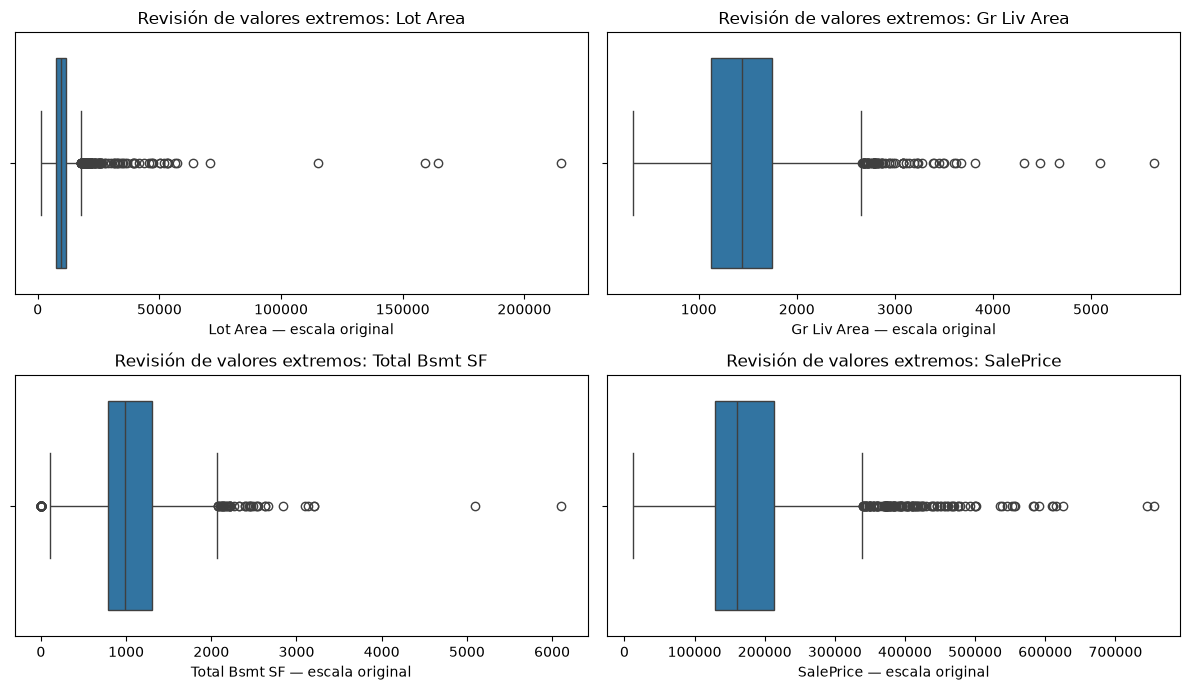

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, columna in zip(axes.flat, variables_revisar):
    sns.boxplot(
        data=df,
        x=columna,
        ax=ax,
        whis=1.5
    )

    ax.set_title(f"Revisión de valores extremos: {columna}")
    ax.set_xlabel(f"{columna} — escala original")

plt.tight_layout()
plt.show()

#### Resultado de la revisión de valores extremos

La regla de 1,5 × IQR identificó observaciones potencialmente atípicas
en las cuatro variables analizadas:

- Lot Area: 127 registros (4,33%).
- Gr Liv Area: 75 registros (2,56%).
- Total Bsmt SF: 123 registros (4,20%).
- SalePrice: 137 registros (4,68%).

Las cantidades corresponden a cada variable por separado y pueden
incluir las mismas viviendas.

Los gráficos muestran valores elevados alejados del rango central
en superficies y precios. Sin embargo, esto no demuestra que sean
errores: podrían representar propiedades con características
poco frecuentes.

En Total Bsmt SF, el límite inferior es 29,50. Por tanto, la regla
también marca superficies iguales a cero. Se deberá comprobar si
estos registros corresponden a viviendas sin sótano antes de
considerarlos inconsistentes.

En SalePrice, los registros marcados se encuentran por encima del
límite superior de 339.500, ya que el precio mínimo observado supera
el límite inferior de 3.500.

No se eliminarán ni modificarán registros únicamente por superar
los límites IQR. Estos resultados se utilizarán como diagnóstico
exploratorio, no como umbrales definitivos de limpieza.

### 2.8. Conclusiones del diagnóstico inicial

1. El dataset contiene 2.930 registros y 82 columnas.

2. No se detectaron filas completamente duplicadas ni repeticiones
   en los identificadores Order y PID.

3. SalePrice no presenta valores ausentes, iguales a cero ni negativos.

4. La lectura inicial de valores ausentes mezcla campos vacíos con
   códigos como "NA" y "None". Su tratamiento deberá considerar
   el significado de cada variable.

5. Se identificaron cuatro registros con alertas temporales.
   Destaca Garage Yr Blt = 2207, sin evidencia suficiente para
   asignarle directamente un año correcto.

6. Se detectaron posibles valores extremos en superficies y precios.
   No se consideran errores automáticamente.

El dataset original se mantiene sin modificaciones. Las decisiones
de limpieza y transformación se implementarán posteriormente en
src/data_prep.py y se justificarán en este notebook.